In [1]:

import pandas as pd

# Load the customer dataset
df = pd.read_csv('/content/Mall_Customers.csv')

# Display the first five rows
df.head()


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [2]:

# Check the dataset size
print("Dataset Shape:", df.shape)

# Check column names and data types
df.info()

# Check for missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Check for duplicate rows
print("\nDuplicate Rows:", df.duplicated().sum())


Dataset Shape: (200, 5)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB

Missing Values:
CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

Duplicate Rows: 0


Summary Statistics:


,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000



Customer Count by Gender:
Gender
Female    112
Male       88
Name: count, dtype: int64


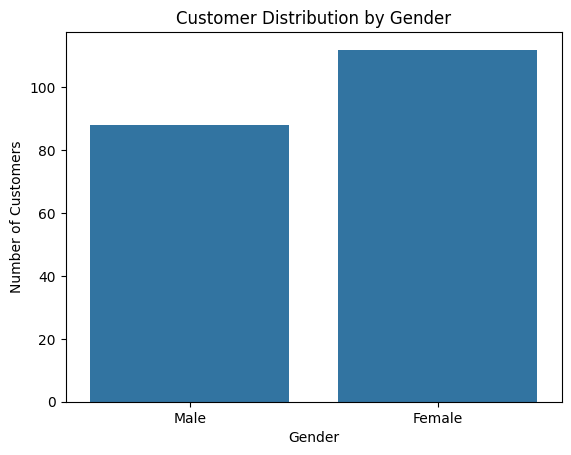

In [3]:

# Display summary statistics
print("Summary Statistics:")
display(df.describe())

# Count customers by gender
print("\nCustomer Count by Gender:")
print(df["Gender"].value_counts())

# Visualize customer gender distribution
import matplotlib.pyplot as plt
import seaborn as sns

sns.countplot(data=df, x="Gender")
plt.title("Customer Distribution by Gender")
plt.xlabel("Gender")
plt.ylabel("Number of Customers")
plt.show()


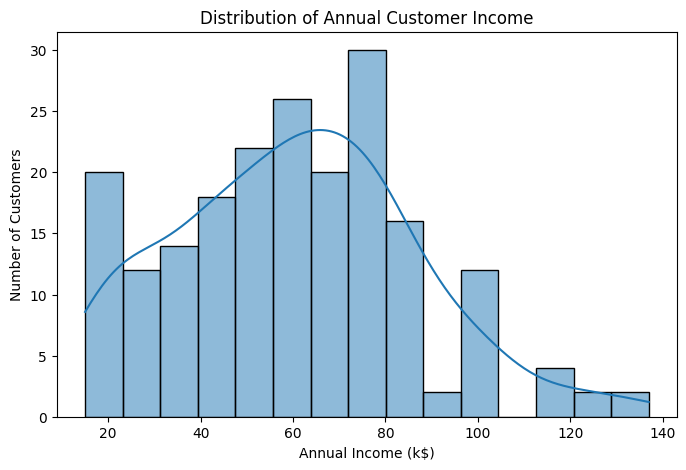

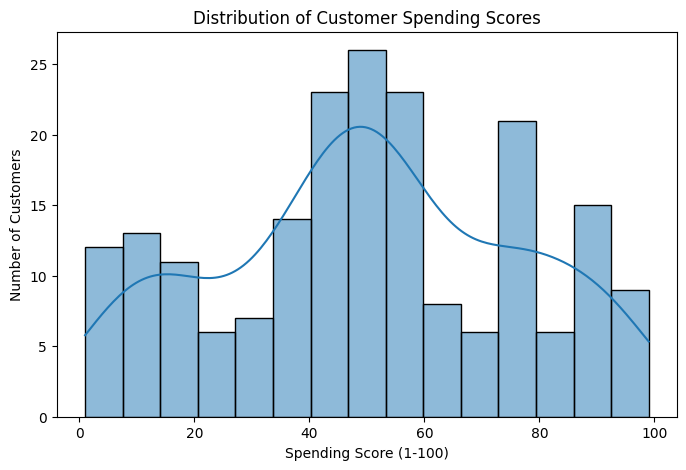

In [4]:

# Chart 1: Distribution of Annual Income
plt.figure(figsize=(8, 5))
sns.histplot(data=df, x="Annual Income (k$)", bins=15, kde=True)
plt.title("Distribution of Annual Customer Income")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Number of Customers")
plt.show()

# Chart 2: Distribution of Spending Score
plt.figure(figsize=(8, 5))
sns.histplot(data=df, x="Spending Score (1-100)", bins=15, kde=True)
plt.title("Distribution of Customer Spending Scores")
plt.xlabel("Spending Score (1-100)")
plt.ylabel("Number of Customers")
plt.show()


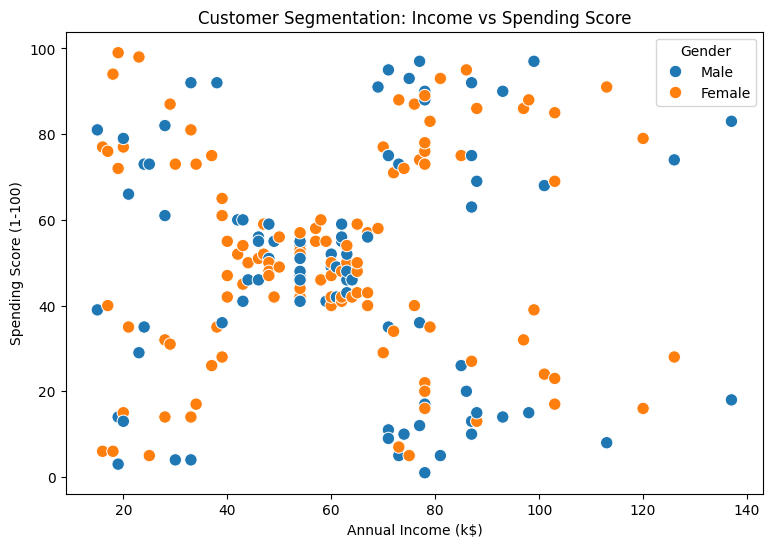

In [5]:

# Scatter plot: Annual Income vs Spending Score

plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=df,
    x="Annual Income (k$)",
    y="Spending Score (1-100)",
    hue="Gender",
    s=80
)

plt.title("Customer Segmentation: Income vs Spending Score")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.legend(title="Gender")
plt.show()


In [6]:

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

# Select features for customer segmentation
X = df[["Annual Income (k$)", "Spending Score (1-100)"]]

# Scale the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Features selected:", list(X.columns))
print("Original data shape:", X.shape)
print("Scaled data shape:", X_scaled.shape)
print("Data preparation completed successfully!")


Features selected: ['Annual Income (k$)', 'Spending Score (1-100)']
Original data shape: (200, 2)
Scaled data shape: (200, 2)
Data preparation completed successfully!


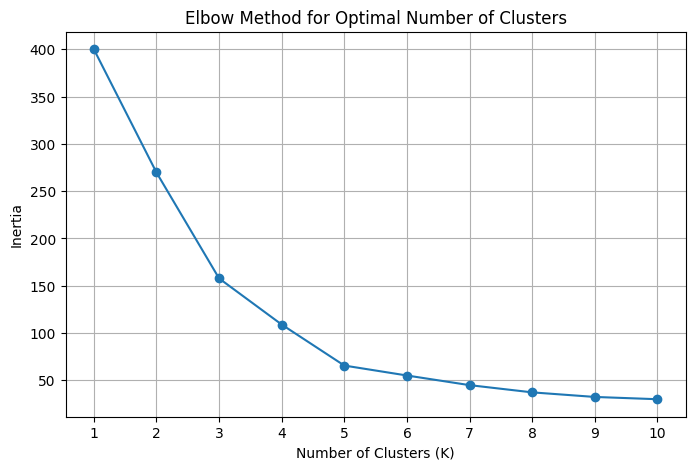

In [7]:

# Elbow Method to find the best number of clusters

inertia = []

for k in range(1, 11):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    inertia.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), inertia, marker="o")
plt.title("Elbow Method for Optimal Number of Clusters")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.xticks(range(1, 11))
plt.grid(True)
plt.show()


In [8]:

# Train the K-Means clustering model

kmeans = KMeans(n_clusters=5, random_state=42, n_init=10)

# Assign a cluster to each customer
df["Cluster"] = kmeans.fit_predict(X_scaled)

# Display the first five customers with their cluster labels
display(df.head())

# Count customers in each cluster
print("Customers in Each Cluster:")
print(df["Cluster"].value_counts().sort_index())


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100),Cluster
0,1,Male,19,15,39,4
1,2,Male,21,15,81,2
2,3,Female,20,16,6,4
3,4,Female,23,16,77,2
4,5,Female,31,17,40,4


Customers in Each Cluster:
Cluster
0    81
1    39
2    22
3    35
4    23
Name: count, dtype: int64


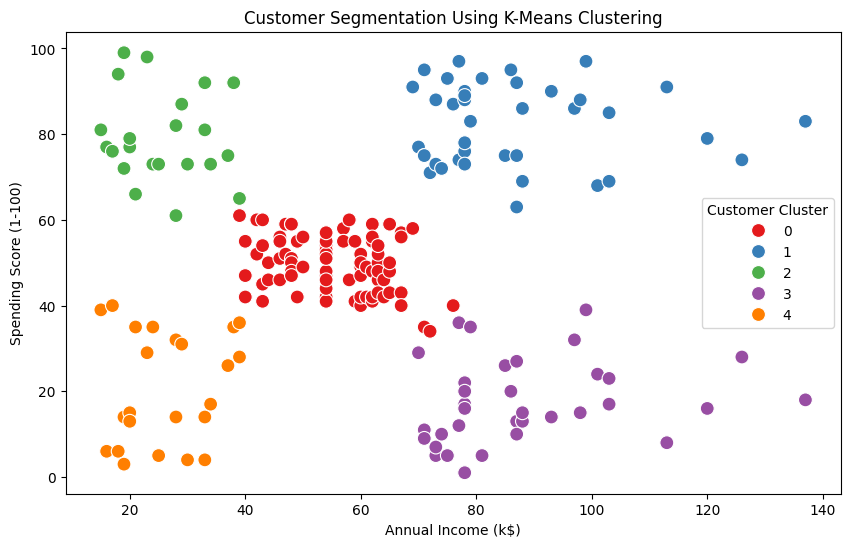

In [9]:

# Visualize customer segments

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="Annual Income (k$)",
    y="Spending Score (1-100)",
    hue="Cluster",
    palette="Set1",
    s=100
)

plt.title("Customer Segmentation Using K-Means Clustering")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.legend(title="Customer Cluster")
plt.show()


In [10]:

# Analyze customer segments

cluster_summary = df.groupby("Cluster").agg(
    Customer_Count=("CustomerID", "count"),
    Average_Age=("Age", "mean"),
    Average_Income=("Annual Income (k$)", "mean"),
    Average_Spending_Score=("Spending Score (1-100)", "mean")
).round(2)

display(cluster_summary)


,Customer_Count,Average_Age,Average_Income,Average_Spending_Score
Cluster,,,,
0,81,42.72,55.30,49.52
1,39,32.69,86.54,82.13
2,22,25.27,25.73,79.36
3,35,41.11,88.20,17.11
4,23,45.22,26.30,20.91


In [11]:

# Generate business insights for each customer segment

for cluster_id, row in cluster_summary.iterrows():
    print(f"\nCustomer Segment {cluster_id}")
    print(f"Number of customers: {row['Customer_Count']:.0f}")
    print(f"Average age: {row['Average_Age']:.1f}")
    print(f"Average annual income: ${row['Average_Income']:.1f}k")
    print(f"Average spending score: {row['Average_Spending_Score']:.1f}")

print("\nBusiness Recommendations:")
print("1. Use targeted marketing for different customer segments.")
print("2. Design loyalty programs for customers with high spending scores.")
print("3. Consider suitable promotions to engage lower-spending customers.")
print("4. Review each segment's income and spending patterns before planning campaigns.")



Customer Segment 0
Number of customers: 81
Average age: 42.7
Average annual income: $55.3k
Average spending score: 49.5

Customer Segment 1
Number of customers: 39
Average age: 32.7
Average annual income: $86.5k
Average spending score: 82.1

Customer Segment 2
Number of customers: 22
Average age: 25.3
Average annual income: $25.7k
Average spending score: 79.4

Customer Segment 3
Number of customers: 35
Average age: 41.1
Average annual income: $88.2k
Average spending score: 17.1

Customer Segment 4
Number of customers: 23
Average age: 45.2
Average annual income: $26.3k
Average spending score: 20.9

Business Recommendations:
1. Use targeted marketing for different customer segments.
2. Design loyalty programs for customers with high spending scores.
3. Consider suitable promotions to engage lower-spending customers.
4. Review each segment's income and spending patterns before planning campaigns.


In [12]:

# Export the segmented customer dataset

df.to_csv("Customer_Segmentation_Results.csv", index=False)

print("Customer segmentation results saved successfully!")


Customer segmentation results saved successfully!


In [13]:

from google.colab import files
files.download("Customer_Segmentation_Results.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

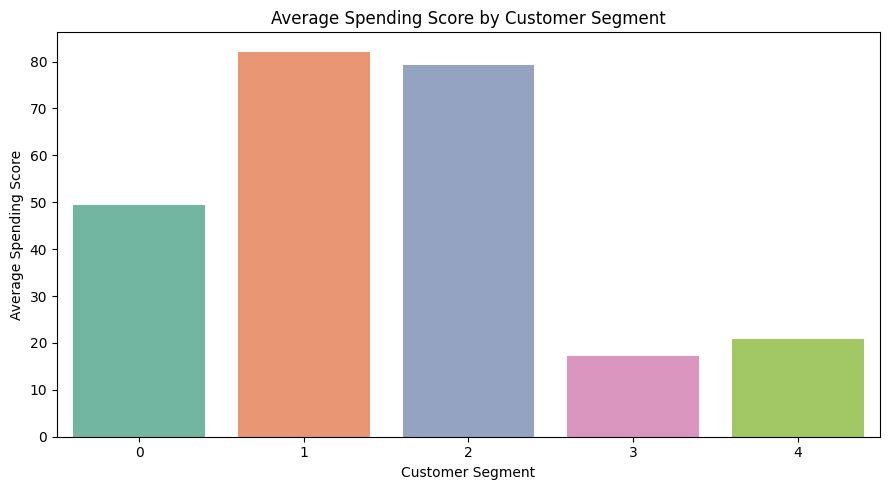

In [14]:

# Average spending score by customer segment

plt.figure(figsize=(9, 5))

sns.barplot(
    data=df,
    x="Cluster",
    y="Spending Score (1-100)",
    hue="Cluster",
    palette="Set2",
    legend=False,
    errorbar=None
)

plt.title("Average Spending Score by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Average Spending Score")
plt.tight_layout()
plt.show()


In [15]:

# Calculate average income and spending score for each cluster
cluster_summary = df.groupby("Cluster").agg(
    Average_Income=("Annual Income (k$)", "mean"),
    Average_Spending=("Spending Score (1-100)", "mean")
)

# Give each cluster a descriptive label
def label_segment(row):
    if row["Average_Income"] >= 55 and row["Average_Spending"] >= 60:
        return "High Income - High Spending"
    elif row["Average_Income"] >= 55 and row["Average_Spending"] < 40:
        return "High Income - Low Spending"
    elif row["Average_Income"] < 40 and row["Average_Spending"] >= 60:
        return "Low Income - High Spending"
    elif row["Average_Income"] < 40 and row["Average_Spending"] < 40:
        return "Low Income - Low Spending"
    else:
        return "Average Customer Segment"

# Map labels to customers
cluster_summary["Segment_Label"] = cluster_summary.apply(
    label_segment, axis=1
)

df["Segment_Label"] = df["Cluster"].map(
    cluster_summary["Segment_Label"]
)

# Display the results
display(cluster_summary)
display(df.head())

# Save the updated dataset
df.to_csv("Customer_Segmentation_Results.csv", index=False)

print("Customer labels added and dataset saved!")


,Average_Income,Average_Spending,Segment_Label
Cluster,,,
0,55.296296,49.518519,Average Customer Segment
1,86.538462,82.128205,High Income - High Spending
2,25.727273,79.363636,Low Income - High Spending
3,88.200000,17.114286,High Income - Low Spending
4,26.304348,20.913043,Low Income - Low Spending


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100),Cluster,Segment_Label
0,1,Male,19,15,39,4,Low Income - Low Spending
1,2,Male,21,15,81,2,Low Income - High Spending
2,3,Female,20,16,6,4,Low Income - Low Spending
3,4,Female,23,16,77,2,Low Income - High Spending
4,5,Female,31,17,40,4,Low Income - Low Spending


Customer labels added and dataset saved!
